#  <center>Exploratory Data Analysis of game balance between races in Starcraft 2

## <Center>What is Starcraft 2?

<Center><img src="sc2.avif">


StarCraft 2 is a real-time strategy game developed and published by Blizzard Entertainment which came out on the 27th of July 2010.
It is the sequel to their original game StarCraft that was released in 1998. 

The gameplay involves the player selecting 1 of 3 factions, The Terrans, Protoss or Zerg to gather resources, construct a base and create an army to complete objectives or eliminate an enemy.

### Aims and Objectives :

The aim of this research is to see how balanced the win rates are between the 3 factions across the whole competetive scene from season 48 - 60 (19 July 2021 - 10 November 2024 ) and across the 3 main regions. North America, Europe and South Korea

I will be specifically looking into 3 things : 
1. Looking into disparities in win rates between regions
2. Assessing the impact of skill level in Race Balance
3. Exploring the impact of race design and win rates


Aquiring and using Dataset :

I will be obtaining the data from nonapa.com which is a community run website that utilizes the official StarCraft 2 game data API directly from Blizzard.

With this data I will be using graphs to observe possible disparities between the different races at different points throughout the last few years of the game's lifespan

### Summary of Area of Research : 

This data analysis project is focused on observing the win rates between different factions across all combined skill groups to determine how balanced they are against each other at different points


### Imports

In [1]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import urllib3

# Suppress only the single InsecureRequestWarning from urllib3 needed
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

C:\Users\Enzo\AppData\Local\Temp\ipykernel_14128\661271326.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


### Relevancy of data and justification for using it
Nonapa.com is one of the best sources for any StarCraft 2 seasonal data as they get the data directly from the APIs that Blizzard themselves have provided. It is also a great middle ground of accessing the APIs as they regularly update and extract the most important information for statistics and analysis.

### Ethics of use of data

The data scrapped comes from a community project that uses the official Blizzard API
https://nonapa.com
The Blizzard API use terms and conditions as well as guides for using them are found on their website
https://develop.battle.net/documentation/guides
https://www.blizzard.com/en-us/legal/a2989b50-5f16-43b1-abec-2ae17cc09dd6/blizzard-developer-api-terms-of-use


### Potenential Biases of Dataset
I do not believe that there is much bias in the data as the individual data points gathered and compiled are between players playing in the same chosen region. For example, if you play in the EU region, you will only play against people in the EU region. There is no direct crossplay between the regions for the competetive gamemode. There are however some people who chose to play in a region other than their own. We are unable to pick out these kinds of data to see how the win rates are between regions. For example being able to compare a Platinum player from NA and a Platinum player from South Korea. The only few known people that do these kinds of matchups are the professional players that play in tournaments. These people are on the most extreme end of the skill spectrum that the region does not matter anymore, and only the player's skill matters.

### Project Background

#### Why is this field of interest to me?
I have chosen this topic for my research as I grew up playing Blizzard games since I was young. I've also been getting back into the game recently, both as a player and an avid viewer. The main inspiration sparked from watching professional players and the discourse within the community about game balance as there have been no 1st place Protoss winners in the premier competitions and only 1 in the majors this year.

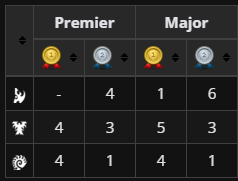

Because of this, I became curious on wether or not this unbalance mainly appears in the most highest of skill levels or throught players of all skill disparities.

### Previous exploration of topic

In terms of exploring win disparites and game balance between the 3 races, there are very few data exploration analysis like this one that I am attempting to do. Online on places like youtube however, there are people constantly making videos about the game. Wether it be about the game balance, community sentiments or possible changes to the game that can be made. I believe that because of online content like this, people don't really need to do a deep dive into the data as taking the current issues people are having is more important and easily understandable.

### Scope of work
I will mainly be focusing on the spread of win rates between the different races across all skill levels together over the last few years as this is an exploration of the state of game balance as a whole. The date range was chosen (19 July 2021 - 10 November 2024) as this is as far back as nonapa goes. It would have been really nice to go even further back as the game had some very unbalanced units earlier on. https://youtu.be/6iiu-9RtIZU?si=UL_9ENaLejEd8gNm Here is a video going through some of the major pain points people had with the game across the years if you are interested. 

They actually also have some data from those playing in the China region but this data only goes until season 54 which ended 1st April 2023 and the player count is many times smaller than the other 3 regions

 As much as I would like to delve deeper and see what other factors could be closely correlated to the win rates, that data is not easily accessed in terms of both time and effort.

### Consideration of other datasets

In terms of other possible datasets to use for this project, there are not that many out there. There are however 2 prominent that contain very extensive amounts of data for public use. 
https://github.com/Kaszanas/SC2_Datasets?tab=readme-ov-file this is the first one and has extremely extensive data from many of the tournaments. However, this data requires the use of .py files with PyTorch which is outside of the scope of this assignment.

The data includes every single move that each player makes in the match
<img src="KaszanasDataset.png">

The other possible dataset to use for this assignment is from here https://github.com/wuhuikai/MSC
The size of this data is also way over the limit for this project

<img src="Size.png">

The dataset has a lot of great information that I would be able to use to explain the intricacies of moment to moment gameplay and the many considerations players make to try to gain an advantage over their opponents.
<img src="GFV.png">

### Data Processing and analysis pipeline

1. Scrape the data from nonapa.com tables
2. Organize the data into a dataframe
3. Conduct initial data inspection and management should there be a need to.
4. Plot charts and graphs for data visualization.
5. Create conclusions based on data analysis and state of the game at the time

In [2]:
Percentages = []
Seasons = []
# Range 48 - 61 to get data from seasons 48-60
for seasonID in range(48,61):
        Seasons.append(seasonID)
        nonapa_url = f"https://nonapa.com/balance?season={seasonID}&rank=-1&map=all"
        response = requests.get(nonapa_url,verify=False)
        if response.status_code == 200:
            soup = BeautifulSoup(response.content, 'html.parser')
            # Remove span tags as there is a vs between the 2 percentages we need
            for catch in soup.find_all("span"):
                catch.decompose()  

            # Counter to prevent adding race win percentages when random race is selected          
            i = 0
            Append = True
            for dd in soup.find_all("dd", {"class":"text-center col-6 m-0 p-0"}):    
                # Using regex to get each individual percentage to add to array instead of in pairs  
                for percentage in re.findall(r'-?\d*\.?\d+m?', str(dd.text)):            
                    if Append == True:
                        # Put all win percentages into array to put into dataframe later
                        Percentages.append(float(percentage))
                    if i == 5 or i == 17 or i == 29:
                            Append = False
                    if i == 11 or i == 23:
                            Append = True
                    i = i + 1                 
            print(f"Got data for season {seasonID}")       
        else:
            print(f"Failed to retrieve the page. Status code: {response.status_code}")
print(Percentages)

Got data for season 48
Got data for season 49
Got data for season 50
Got data for season 51
Got data for season 52
Got data for season 53
Got data for season 54
Got data for season 55
Got data for season 56
Got data for season 57
Got data for season 58
Got data for season 59
Got data for season 60
[49.34, 50.66, 51.49, 48.51, 52.92, 47.08, 48.72, 51.28, 50.74, 49.26, 53.02, 46.98, 49.76, 50.24, 51.13, 48.87, 53.01, 46.99, 49.18, 50.82, 50.61, 49.39, 53.4, 46.6, 48.45, 51.55, 50.93, 49.07, 52.09, 47.91, 48.54, 51.46, 51.79, 48.21, 53.45, 46.55, 49.29, 50.71, 51.35, 48.65, 53.52, 46.48, 49.02, 50.98, 49.75, 50.25, 52.73, 47.27, 48.88, 51.12, 51.66, 48.34, 53.39, 46.61, 49.05, 50.95, 51.78, 48.22, 52.92, 47.08, 50.21, 49.79, 51.73, 48.27, 52.4, 47.6, 49.18, 50.82, 51.63, 48.37, 53.68, 46.32, 50.07, 49.93, 52.13, 47.87, 52.98, 47.02, 50.94, 49.06, 50.91, 49.09, 52.08, 47.92, 49.71, 50.29, 51.59, 48.41, 52.96, 47.04, 49.65, 50.35, 51.96, 48.04, 52.72, 47.28, 50.59, 49.41, 52.31, 47.69, 52.2

Create pandas Dataframe and save the data to csv in case of any disruption

In [12]:
# Convert python list into np array for reshaping
TableValues = np.array(Percentages)

# Range should be between 0-100 as the values are in percentages
min_value = 0
max_value = 100

# Check for out-of-bound values
out_of_bound_values = (TableValues < min_value) | (TableValues > max_value)

# Print the indices of out-of-bound values
if np.any(out_of_bound_values):
    print("Out-of-bound values found at indices:")
    print(np.where(out_of_bound_values))
else:
    print("No out-of-bound values found.")

No out-of-bound values found.


In [ ]:
# Convert 1D array into 2D array so it can be turned into pandas dataframe
TableValues = TableValues.reshape(13,18)
columns=["EU_TVZ", "EU_ZVT", "EU_ZVP", "EU_PVZ", "EU_PVT", "EU_TVP", "KR_TVZ", "KR_ZVT", "KR_ZVP", "KR_PVZ", "KR_PVT", "KR_TVP", "NA_TVZ", "NA_ZVT", "NA_ZVP", "NA_PVZ", "NA_PVT", "NA_TVP"]
WinRates = pd.DataFrame(TableValues, columns=columns, index=Seasons)
WinRates.to_csv("WinRates.csv", index=False)

Here is the dataframe from csv incase the bs4 above does not work

In [4]:
WinRates = pd.read_csv("WinRates.csv")
WinRates

,EU_TVZ,EU_ZVT,EU_ZVP,EU_PVZ,EU_PVT,EU_TVP,KR_TVZ,KR_ZVT,KR_ZVP,KR_PVZ,KR_PVT,KR_TVP,NA_TVZ,NA_ZVT,NA_ZVP,NA_PVZ,NA_PVT,NA_TVP
0,49.34,50.66,51.49,48.51,52.92,47.08,48.72,51.28,50.74,49.26,53.02,46.98,49.76,50.24,51.13,48.87,53.01,46.99
1,49.18,50.82,50.61,49.39,53.40,46.60,48.45,51.55,50.93,49.07,52.09,47.91,48.54,51.46,51.79,48.21,53.45,46.55
2,49.29,50.71,51.35,48.65,53.52,46.48,49.02,50.98,49.75,50.25,52.73,47.27,48.88,51.12,51.66,48.34,53.39,46.61
3,49.05,50.95,51.78,48.22,52.92,47.08,50.21,49.79,51.73,48.27,52.40,47.60,49.18,50.82,51.63,48.37,53.68,46.32
4,50.07,49.93,52.13,47.87,52.98,47.02,50.94,49.06,50.91,49.09,52.08,47.92,49.71,50.29,51.59,48.41,52.96,47.04
5,49.65,50.35,51.96,48.04,52.72,47.28,50.59,49.41,52.31,47.69,52.24,47.76,49.42,50.58,51.61,48.39,52.65,47.35
6,49.26,50.74,51.28,48.72,52.56,47.44,48.89,51.11,51.31,48.69,52.26,47.74,49.60,50.40,51.73,48.27,53.22,46.78
7,49.51,50.49,52.05,47.95,52.71,47.29,49.72,50.28,51.02,48.98,52.65,47.35,49.60,50.40,51.33,48.67,53.19,46.81
8,49.40,50.60,51.29,48.71,52.97,47.03,49.63,50.37,50.97,49.03,52.03,47.97,49.32,50.68,51.50,48.50,53.18,46.82
9,49.59,50.41,51.52,48.48,53.18,46.82,49.59,50.41,51.82,48.18,52.60,47.40,49.72,50.28,51.89,48.11,53.18,46.82


In [19]:
WinRates.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 18 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   EU_TVZ  13 non-null     float64
 1   EU_ZVT  13 non-null     float64
 2   EU_ZVP  13 non-null     float64
 3   EU_PVZ  13 non-null     float64
 4   EU_PVT  13 non-null     float64
 5   EU_TVP  13 non-null     float64
 6   KR_TVZ  13 non-null     float64
 7   KR_ZVT  13 non-null     float64
 8   KR_ZVP  13 non-null     float64
 9   KR_PVZ  13 non-null     float64
 10  KR_PVT  13 non-null     float64
 11  KR_TVP  13 non-null     float64
 12  NA_TVZ  13 non-null     float64
 13  NA_ZVT  13 non-null     float64
 14  NA_ZVP  13 non-null     float64
 15  NA_PVZ  13 non-null     float64
 16  NA_PVT  13 non-null     float64
 17  NA_TVP  13 non-null     float64
dtypes: float64(18)
memory usage: 2.0 KB


Since the data scrapped was only percentages, there is not much work needed for clean up. It also comes from an official source with oversight from the community.

In [29]:
# Get the highest and lowest values
highest_values = TableValues.max(axis=0)
lowest_values = TableValues.min(axis=0)

# Print the results
print("Highest win rate")
print(highest_values)

print("Lowest win rate")
print(lowest_values)

print("Difference between highest and lowest win rate : " , (highest_values - lowest_values))

Highest win rate
53.68
Lowest win rate
46.32
Difference between highest and lowest win rate :  7.359999999999999


There is quite a big difference in the highest and lowest win rates recorded for this period

In [20]:
WinRates.mean()

EU_TVZ    49.490000
EU_ZVT    50.510000
EU_ZVP    51.495385
EU_PVZ    48.504615
EU_PVT    53.034615
EU_TVP    46.965385
KR_TVZ    49.537692
KR_ZVT    50.462308
KR_ZVP    51.034615
KR_PVZ    48.965385
KR_PVT    52.386923
KR_TVP    47.613077
NA_TVZ    49.351538
NA_ZVT    50.648462
NA_ZVP    51.584615
NA_PVZ    48.415385
NA_PVT    53.206923
NA_TVP    46.793077
dtype: float64

From this initial view, I can see that Terrans have a lower average win rate against Protoss for all regions. I believe the reason for this is that Terran units when compared to Protoss are not as strong when directly compared 1-1. This would be a bigger issue for lower to mid tier players that are unable to manage and utilize their strengths as efficiently as higher tiered players. Protoss units on the other hand are directly stronger, so they dont need to be managed as well to make good use out of.

The next thing to notice is that Zerg vs Protoss generally goes to the Zerg. Zerg units are easier to make compared to Protoss units as they are cheaper to produce. I believe this helps more players fight against the more expensive Protoss units as they can simply produce more to overwhelm them whithout needing as much tactics to be used.

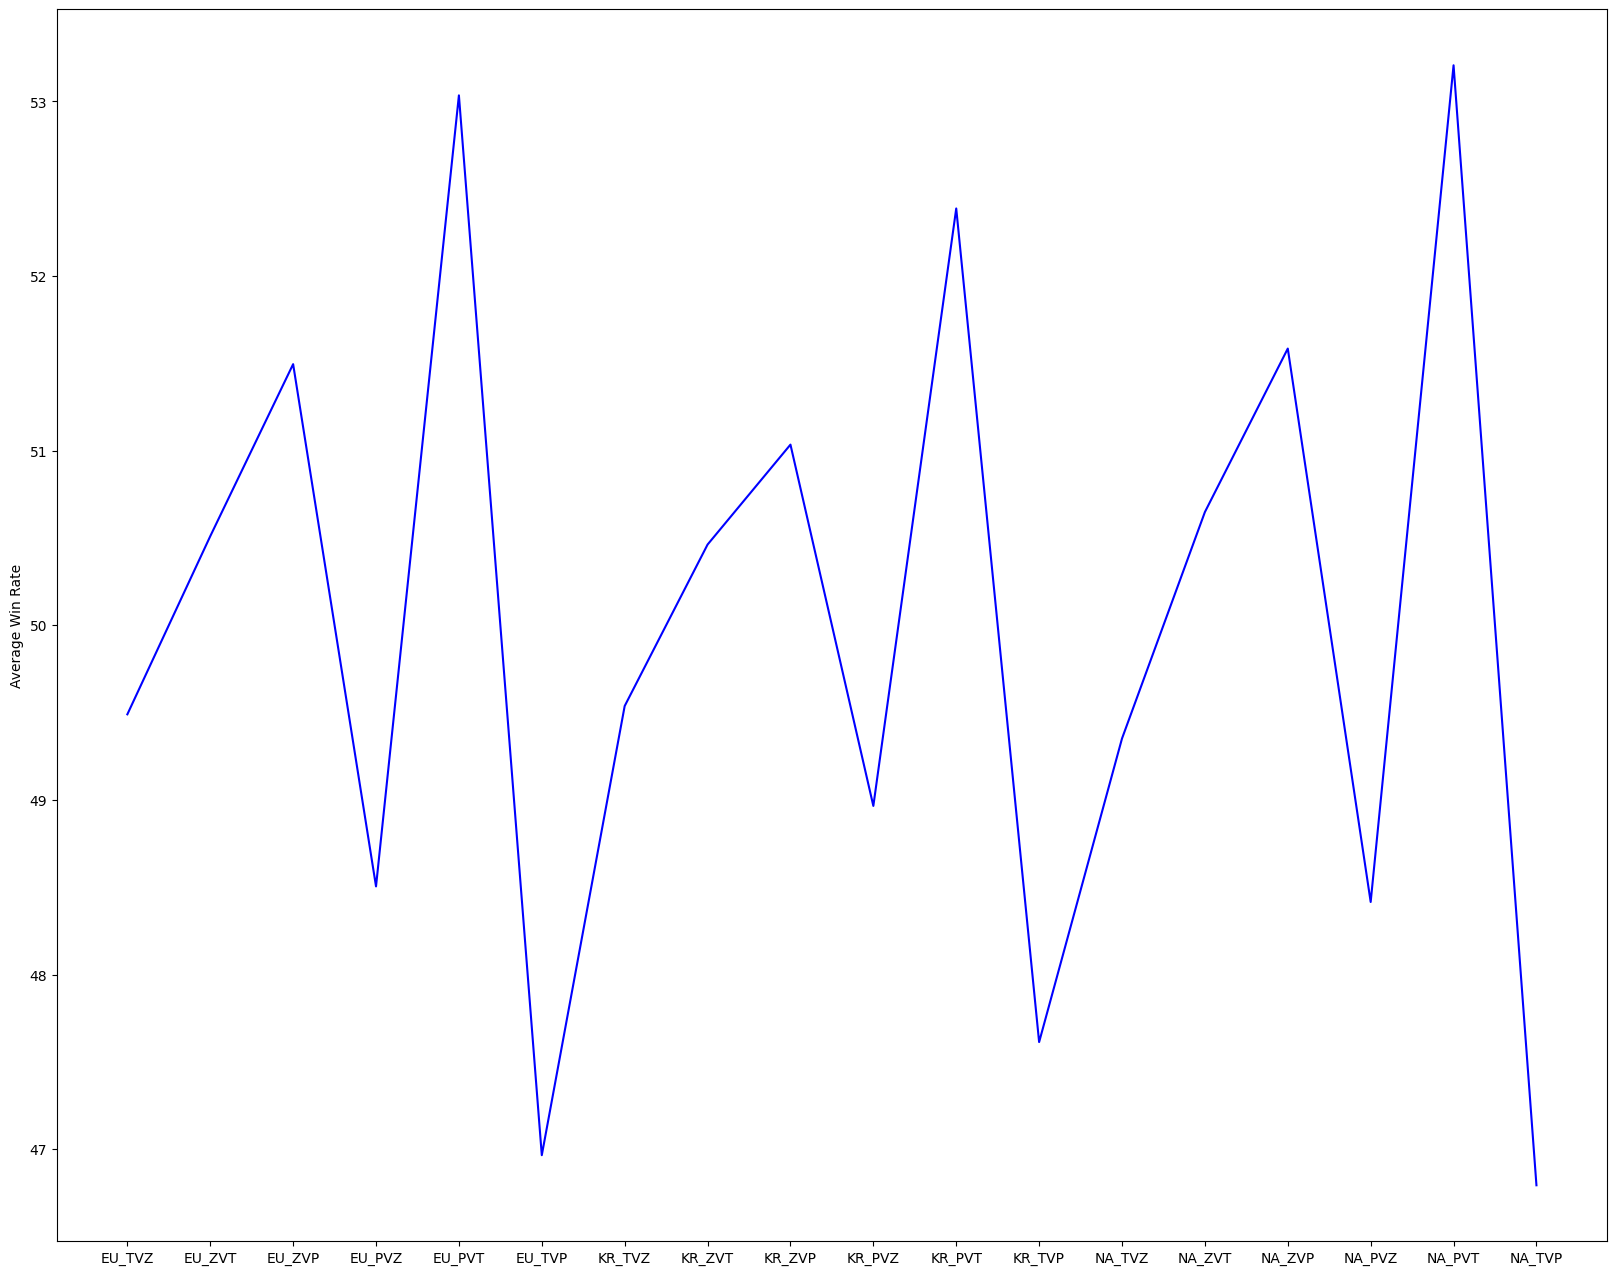

In [21]:
plt.figure(figsize=(20,16))
plt.ylabel("Average Win Rate")
plt.plot(WinRates.mean(), color="b")
plt.show()

This line plot shows the difference in average win rates better. We can see that the win rates fluctuate between ~47% to ~53%

<Axes: >

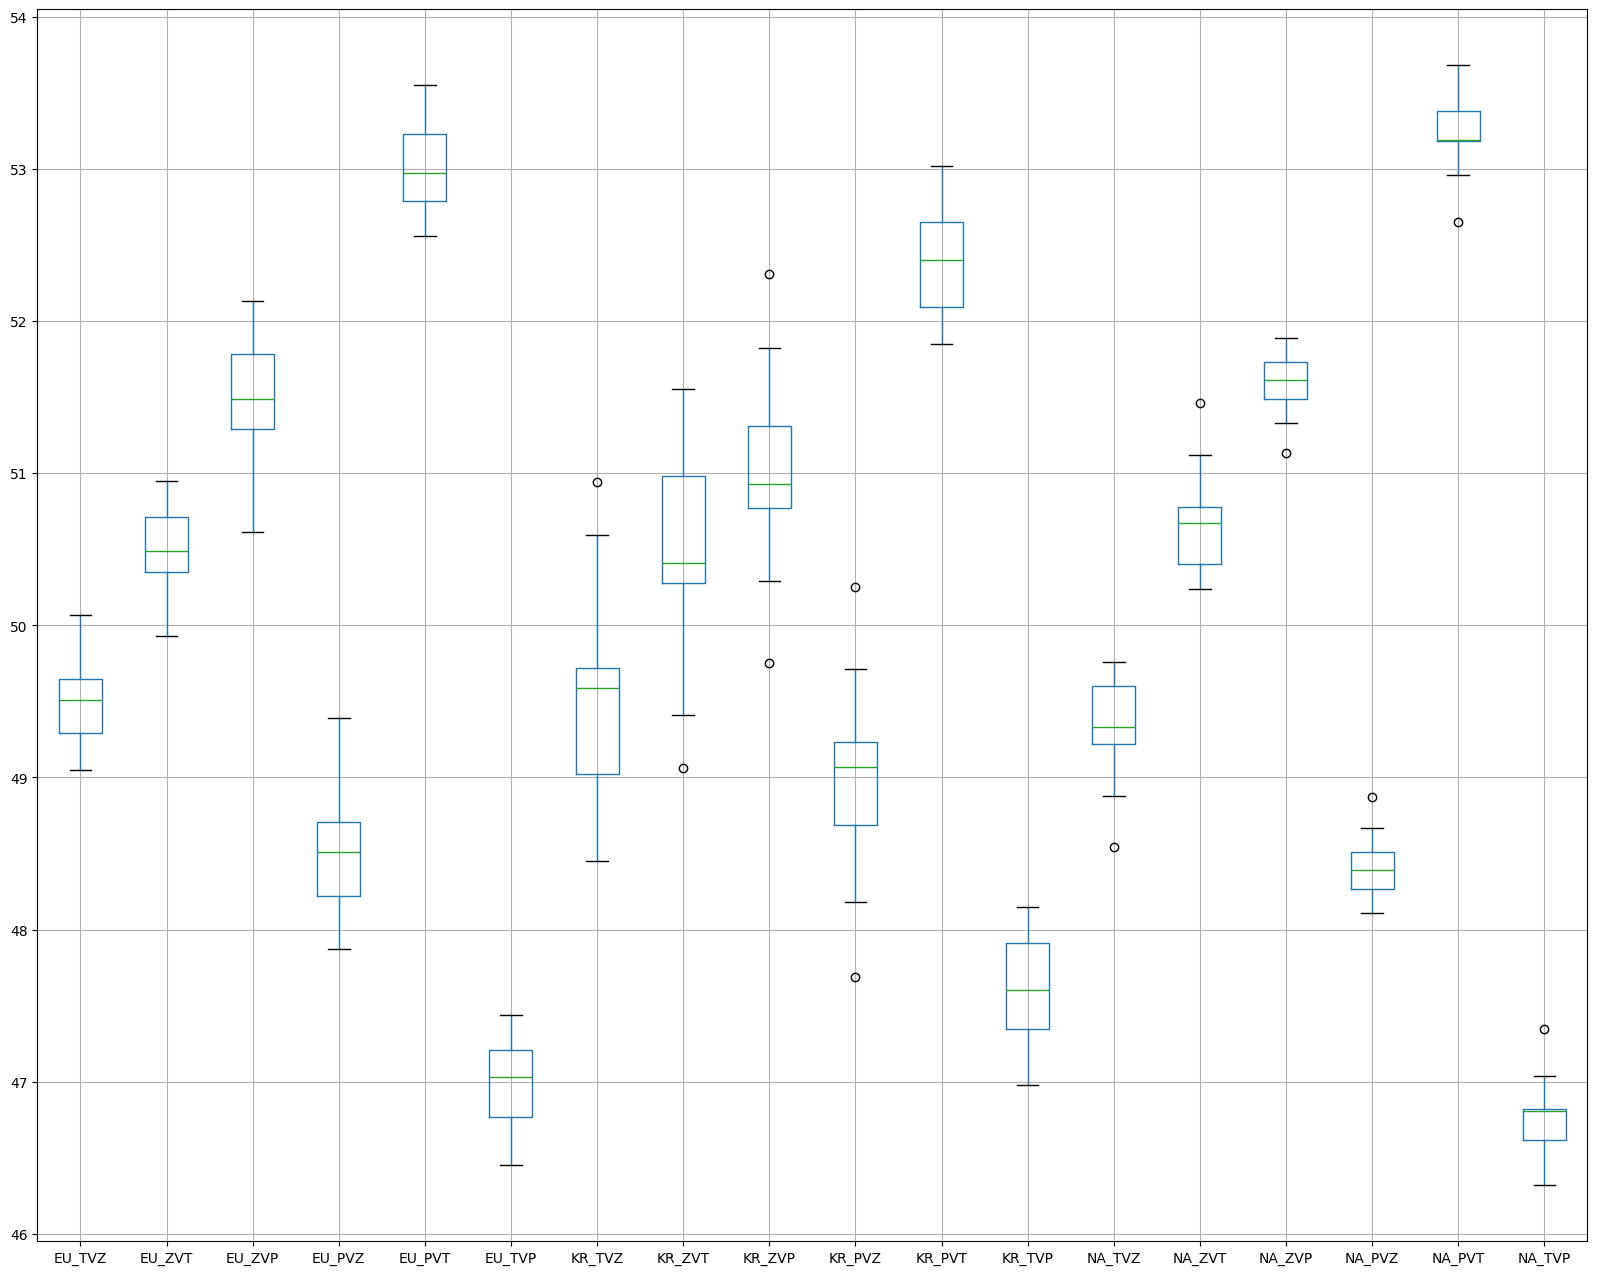

In [22]:
WinRates.boxplot(figsize=(20,16))

From this boxplot, I can see that that there is a lot of disparity between win rates. Both between averages and their ranges. For example, KR_TVZ has a large range of win rates when compared to NA_ZVP. I will do a describe to help see the ranges in numerical form.

In [23]:
WinRates.describe()

,EU_TVZ,EU_ZVT,EU_ZVP,EU_PVZ,EU_PVT,EU_TVP,KR_TVZ,KR_ZVT,KR_ZVP,KR_PVZ,KR_PVT,KR_TVP,NA_TVZ,NA_ZVT,NA_ZVP,NA_PVZ,NA_PVT,NA_TVP
count,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000
mean,49.490000,50.510000,51.495385,48.504615,53.034615,46.965385,49.537692,50.462308,51.034615,48.965385,52.386923,47.613077,49.351538,50.648462,51.584615,48.415385,53.206923,46.793077
std,0.273374,0.273374,0.417625,0.417625,0.318450,0.318450,0.724237,0.724237,0.659123,0.659123,0.335370,0.335370,0.352629,0.352629,0.206221,0.206221,0.251409,0.251409
min,49.050000,49.930000,50.610000,47.870000,52.560000,46.450000,48.450000,49.060000,49.750000,47.690000,51.850000,46.980000,48.540000,50.240000,51.130000,48.110000,52.650000,46.320000
25%,49.290000,50.350000,51.290000,48.220000,52.790000,46.770000,49.020000,50.280000,50.770000,48.690000,52.090000,47.350000,49.220000,50.400000,51.490000,48.270000,53.180000,46.620000
50%,49.510000,50.490000,51.490000,48.510000,52.970000,47.030000,49.590000,50.410000,50.930000,49.070000,52.400000,47.600000,49.330000,50.670000,51.610000,48.390000,53.190000,46.810000
75%,49.650000,50.710000,51.780000,48.710000,53.230000,47.210000,49.720000,50.980000,51.310000,49.230000,52.650000,47.910000,49.600000,50.780000,51.730000,48.510000,53.380000,46.820000
max,50.070000,50.950000,52.130000,49.390000,53.550000,47.440000,50.940000,51.550000,52.310000,50.250000,53.020000,48.150000,49.760000,51.460000,51.890000,48.870000,53.680000,47.350000


For a start, we can see Korean Terran vs Zerg has the largest standard deviation between win rates, close to double of most and even triple of some of them. Another thing to note is the win rates for Terran vs Protoss across all regions as mentioned earlier. While being some of the lowest win rates, they dont deviate much from the average. This leads me to believe what I mentioned at the start about Terran vs Protoss at the lower levels where most players are at being true.

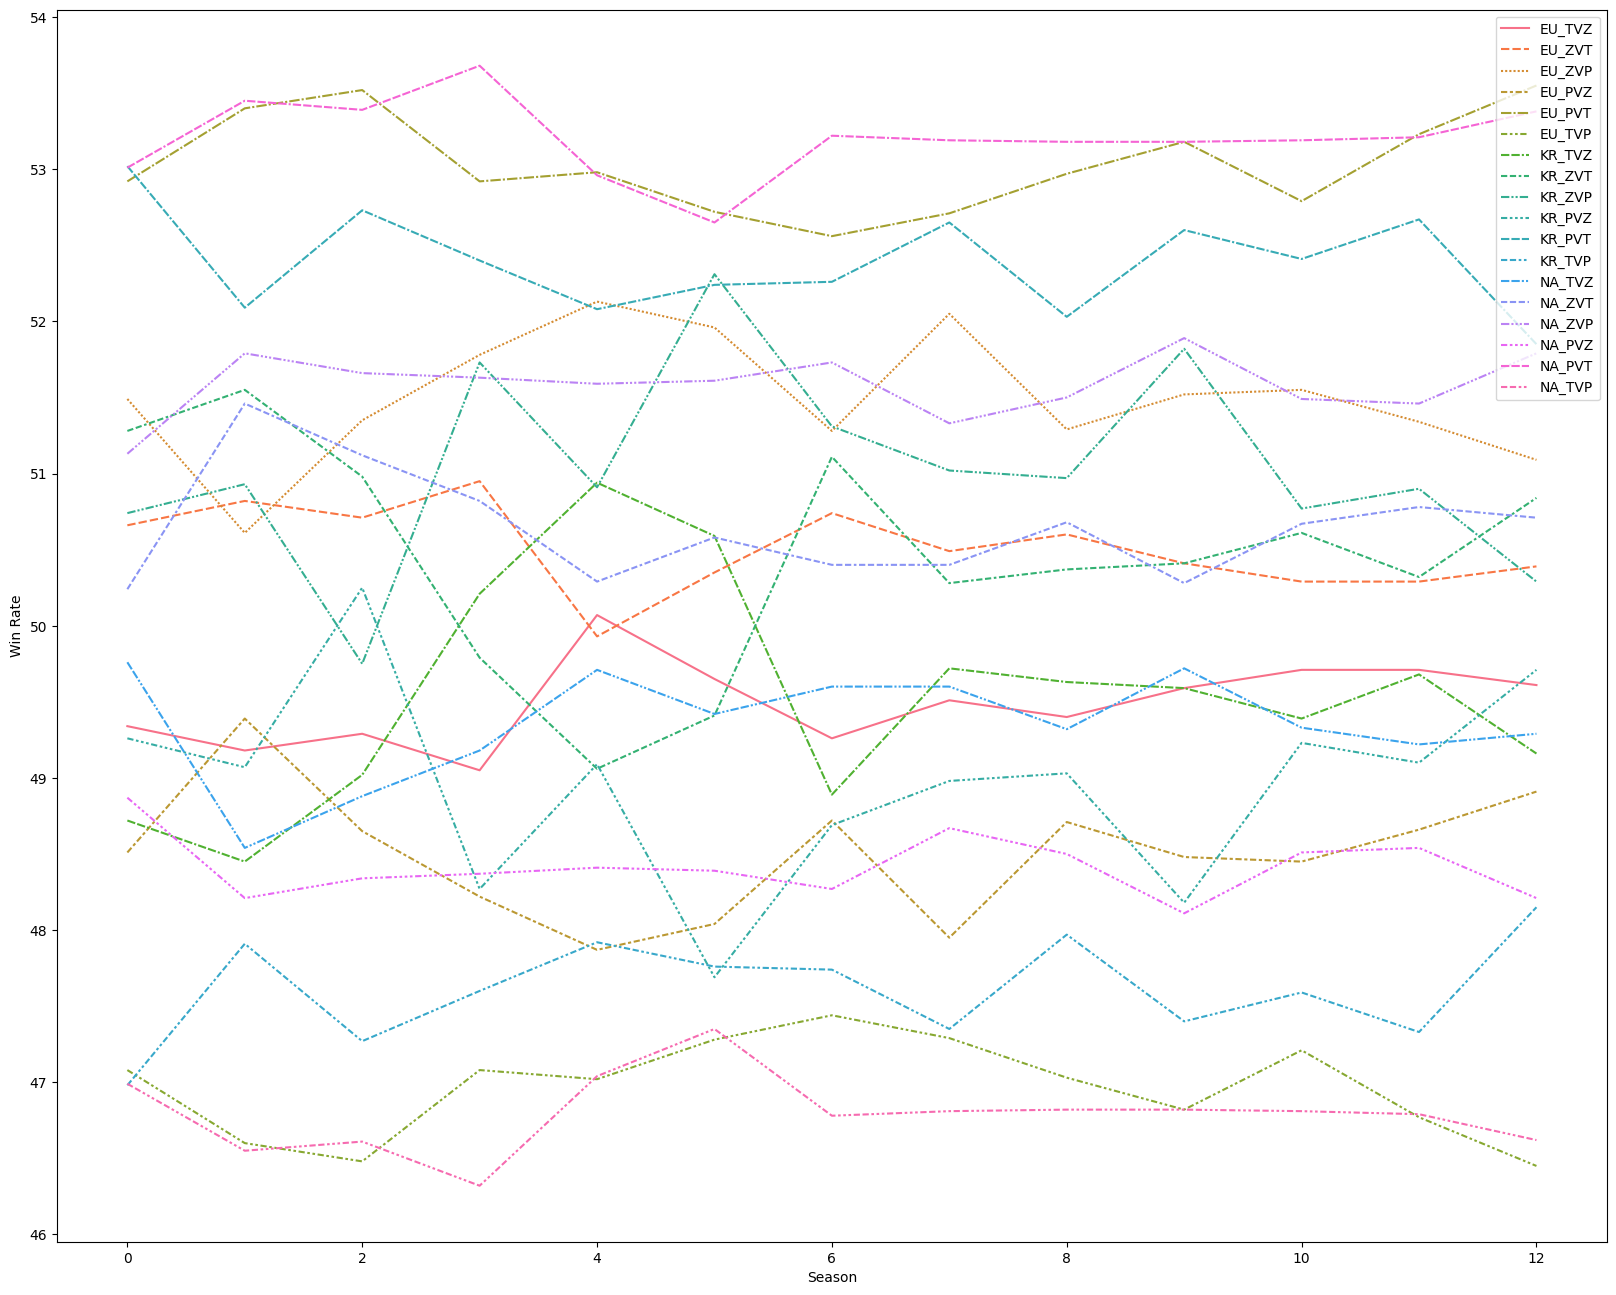

In [24]:
plt.figure(figsize=(20,16))
plt.xlabel("Season")
plt.ylabel("Win Rate")
sns.lineplot(data=WinRates)
plt.show()

The lineplot shows the change in win rates over the seasons. While most of the win rates generally dont fluctuate much, maybe around 1%. The biggest fluctuation noticeable is Korean Terran vs Zerg about 2%. There was a large rise from season 49 to 52 then back down again in 54. There was not much change in the game during that period of time 10 (November 2021 - 5 January 2023). I believe that gradual rise in win rate was due to player skill in general increasing. The StarCraft scene in Korea has been very popular since its launch in 1998 and they are known for being very skilled in general. Since there was little to no changes in this period, people eventually developed better tactics which gave them a better chance at winning the Terran vs Zerg matchup

### Conclusion and closing thoughts
After conducting some analysis on this simple dataset and making some observations. I feel that I can conclude on a surface level that the 3 races are not balanced for the general playerbase. There are nuances to this conclusion however, as the StarCraft games are very complex with many different possibilites and factors to take into consideration when looking into the balance between the 3 races. If i could I would have liked to be able to dive deeper into the individual stats that affect wether or not a player wins in a certain matchup but the amount of space and time needed to process the data is much too large a scope for this assignment.


Overall, I believe this study has helped to visualize people's concerns about game balance as a whole and not just at the professional level where most people watch.